In [1]:
import sys
import os
import pickle
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 0

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)
timestamps = read_utils.get_timestamps(read_utils.get_filepath(path, file_id))

# clear nan values
mask = markers.notna().all(axis=1)

traces = traces[mask]
markers = markers[mask]
states = states[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
#markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

In [5]:
# max_shift_seconds = 5
# max_shift = int(max_shift_seconds * sampling_rates)
#
# print('maximum max_shift_seconds', int(max_shift_seconds))
# print(f'actual max_shift_seconds: {max_shift / sampling_rates:.3f}s')
#
# if max_shift > 0:
# 	markers_shifted = dict()
# 	for marker_label in markers.columns:
# 		for s in range(1, int(max_shift) + 1):
# 			shift_seconds = s / sampling_rates
# 			markers_shifted[f'{marker_label}-{shift_seconds:.2f}s'] = np.pad(markers[marker_label].values[:-s], ((s, 0),))
# 	markers = pd.concat(
# 		[markers, pd.DataFrame(markers_shifted, index=markers.index)], axis=1)

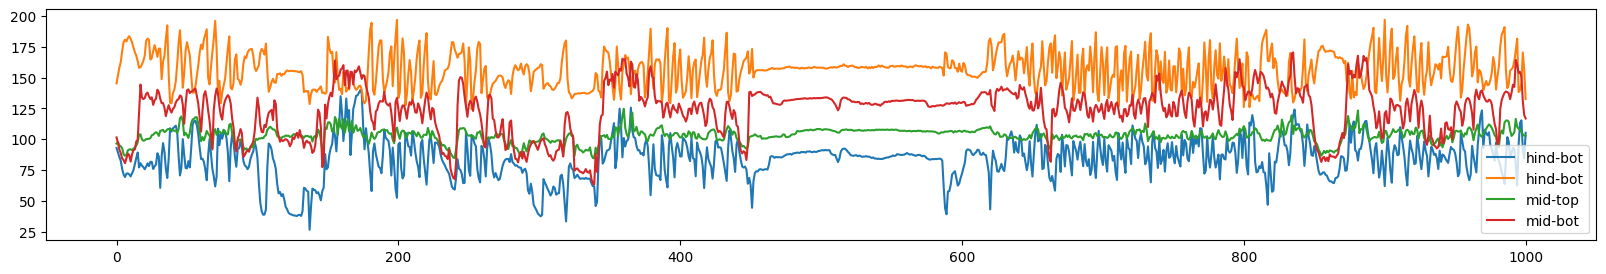

In [30]:
plt.figure(figsize=(20, 3))
plt.plot(markers.loc[:1000, ['hind-bot_x']].values, label='hind-bot')
plt.plot(markers.loc[:1000, ['hind-bot_y']].values, label='hind-bot')
plt.plot(markers.loc[:1000, ['mid-top_x']].values, label='mid-top')
plt.plot(markers.loc[:1000, ['mid-bot_x']].values, label='mid-bot')
# plt.plot(markers.loc[:1000, ['hind-bot_x']].values)
# plt.plot(markers.loc[:1000, ['hind-bot_y']].values)


plt.legend()

# Index(['abdomen-top_x', 'abdomen-top_y', 'abdomen-bot_x', 'abdomen-bot_y',
#        'hind-top_x', 'hind-top_y', 'hind-bot_x', 'hind-bot_y', 'mid-top_x',
#        'mid-top_y', 'mid-bot_x', 'mid-bot_y', 'fore-top_x', 'fore-top_y',
#        'fore-bot_x', 'fore-bot_y'],
#       dtype='str')

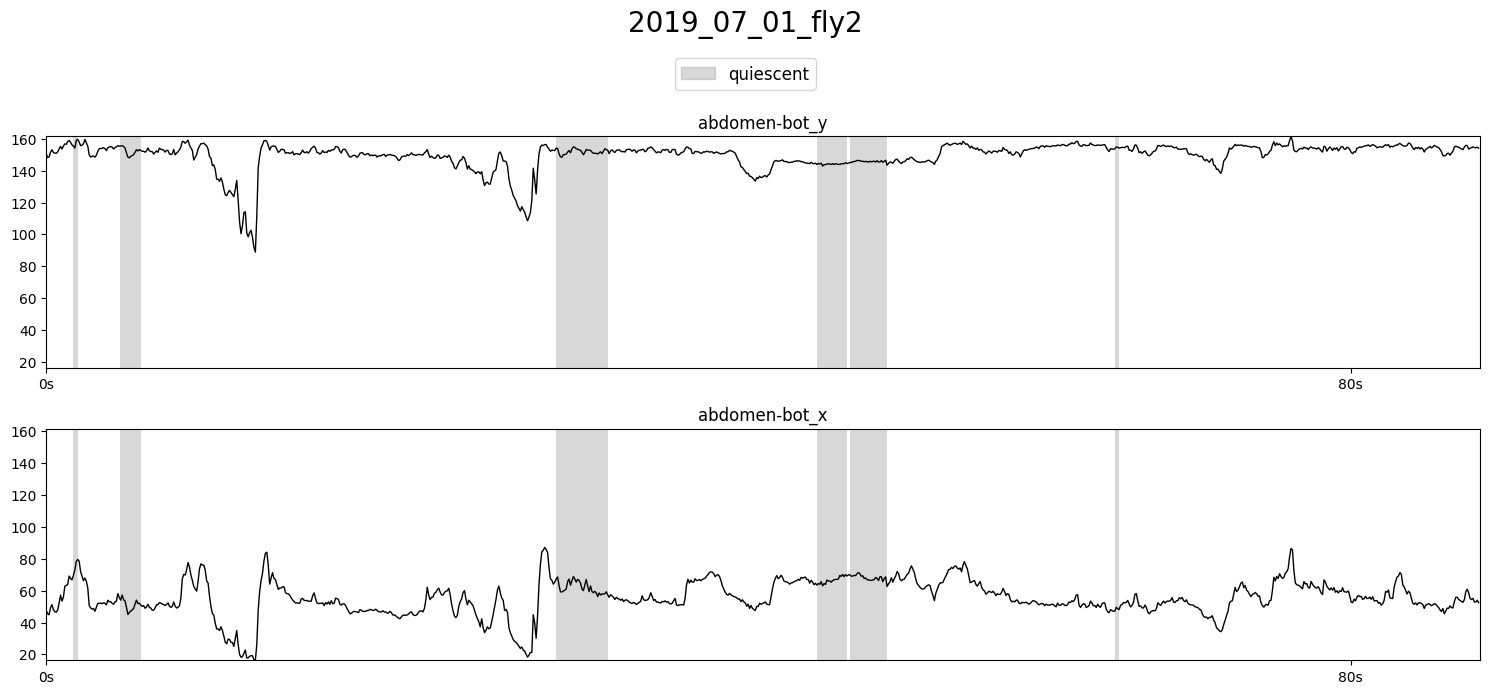

In [38]:
# max_x = markers.values.shape[0]
max_x = 1000

plot_utils.plot_traces(markers.loc[:max_x, ['abdomen-bot_y', 'abdomen-bot_x']],
					   states[['abdomen-move']].loc[:max_x],
					   timestamps,
					   label='quiescent',
					   title=f'{filename}',
					   n_plots=None, plots_per_row=1, top_space=1, ylimits=None)

In [18]:
print(traces.shape)

(10219, 1559)


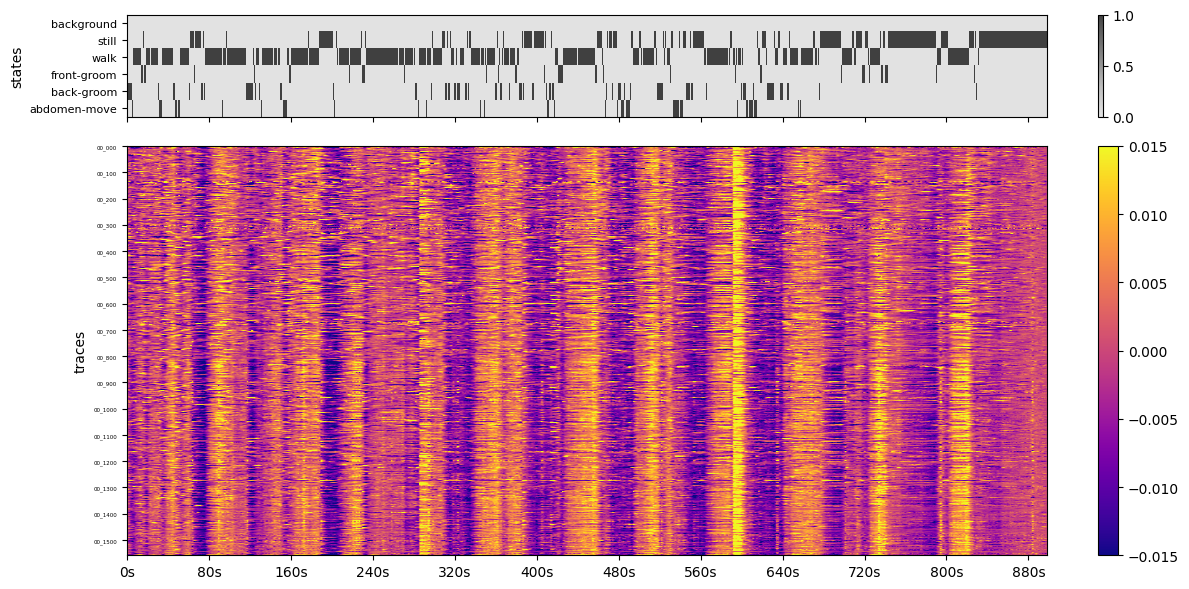

In [20]:
plot_utils.plot_heatmap_stack(
	traces, states, timestamps,
	'traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

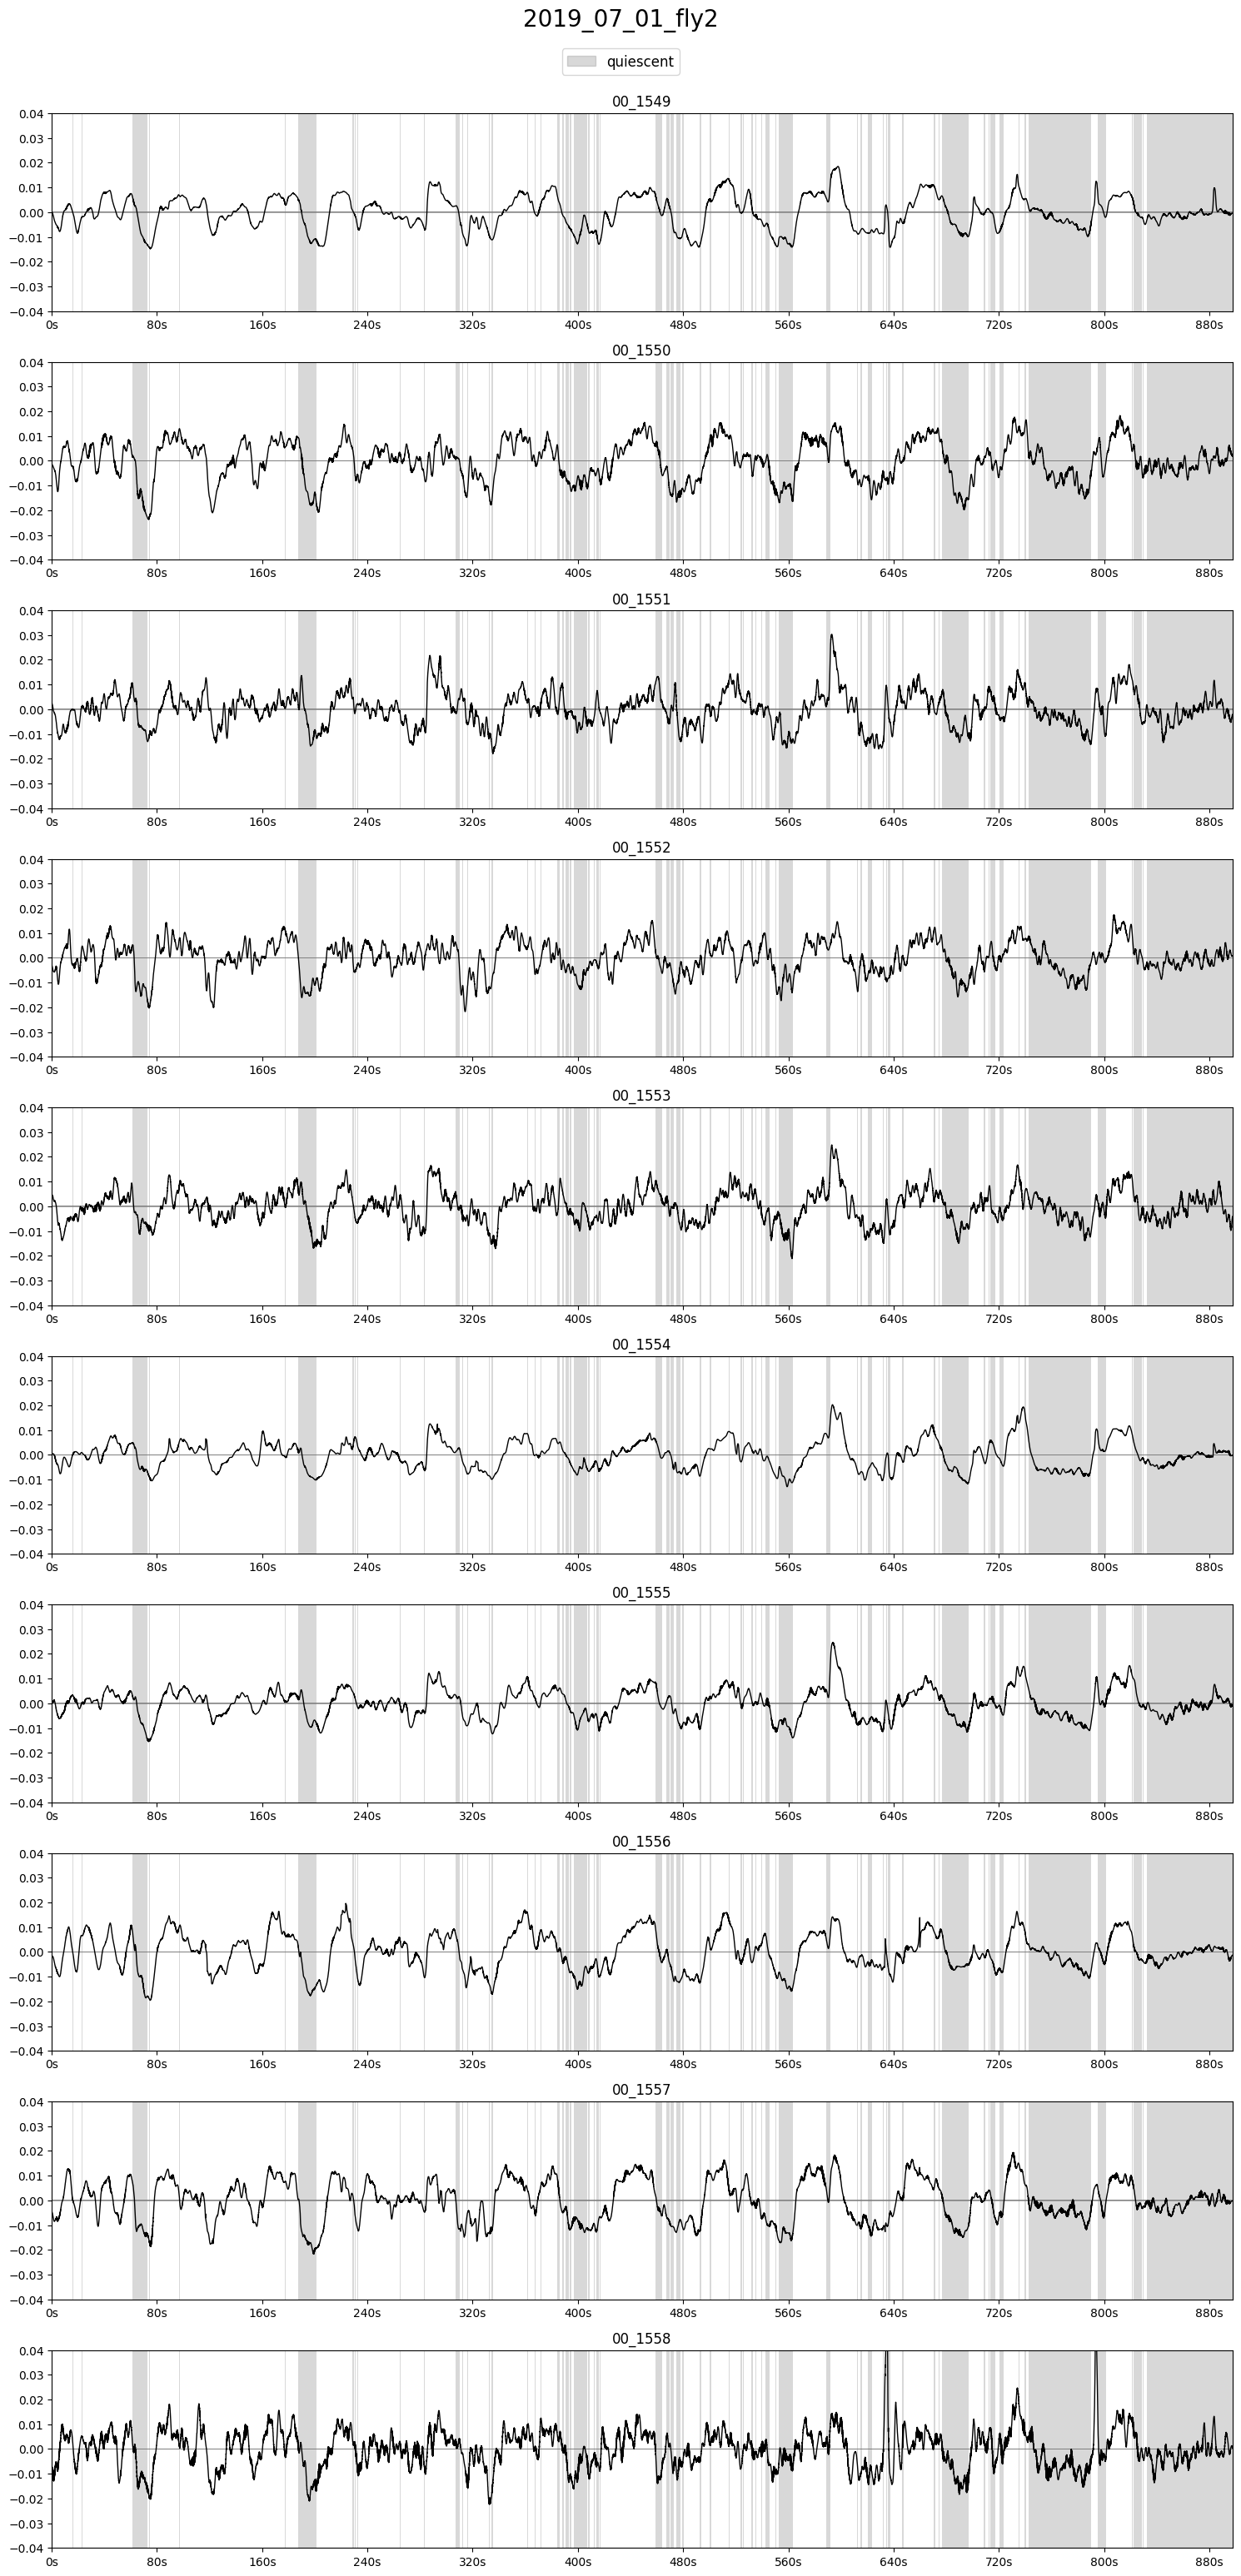

In [7]:
plot_utils.plot_traces(traces.iloc[:, -10:],
					   states['still'],
					   timestamps,
					   label='quiescent',
					   title=f'{filename}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))

In [27]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in [markers]
][0]

# flail

In [22]:
file_id_fl = 4

In [23]:
path_fl = os.path.join(read_utils.get_data_path(), 'brain/incomplete/no_pickle/flailing')

(filename_fl,
 traces_fl,
 states_fl, markers_fl) = read_utils.get_data(path_fl, file_id_fl, with_markers=False)

# # clear nan values
# 	mask = markers_fl.notna().all(axis=1)
#
# 	traces_fl = traces_fl[mask]
# 	markers_fl = markers_fl[mask]
# 	states_fl = states_fl[mask]

# naive ID unknown neurons
traces_fl.columns = pd.Index([
	f'{file_id_fl:02d}_{n_id:03d}' if empty or type(label) is not str  else label for n_id, (label, empty) in enumerate(zip(traces_fl.columns, traces_fl.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rates, 1 / 100), columns=traces.columns)
markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

In [24]:
print(traces_fl.shape)

(9184, 2376)


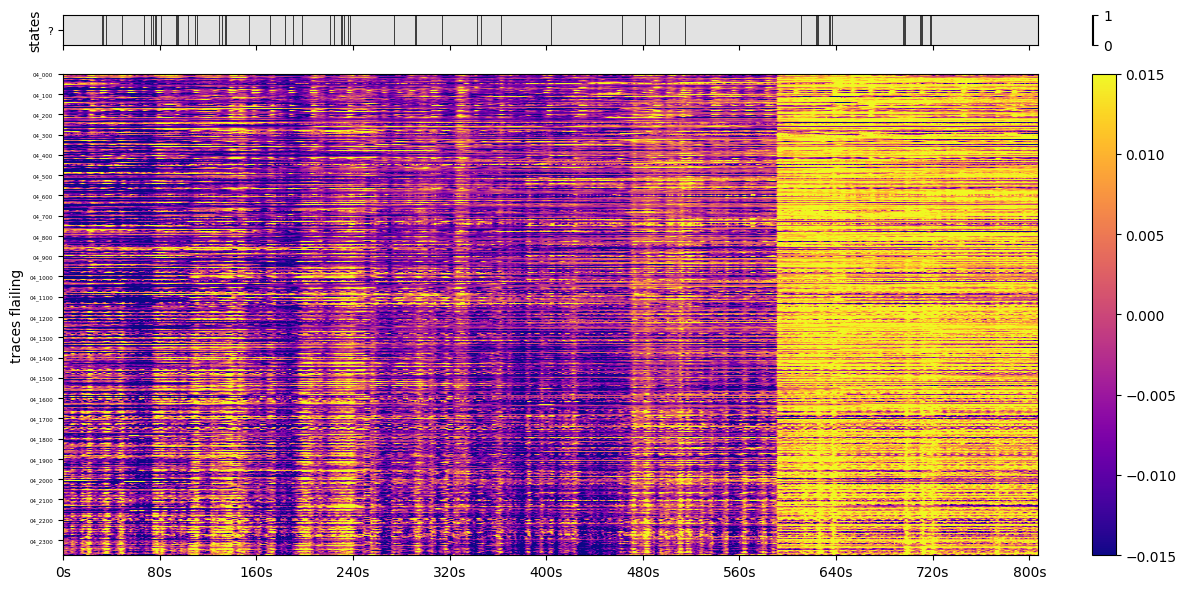

In [25]:
plot_utils.plot_heatmap_stack(
	traces_fl, states_fl[['?']], timestamps,
	'traces flailing', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False, height_ratios=(1, 16))

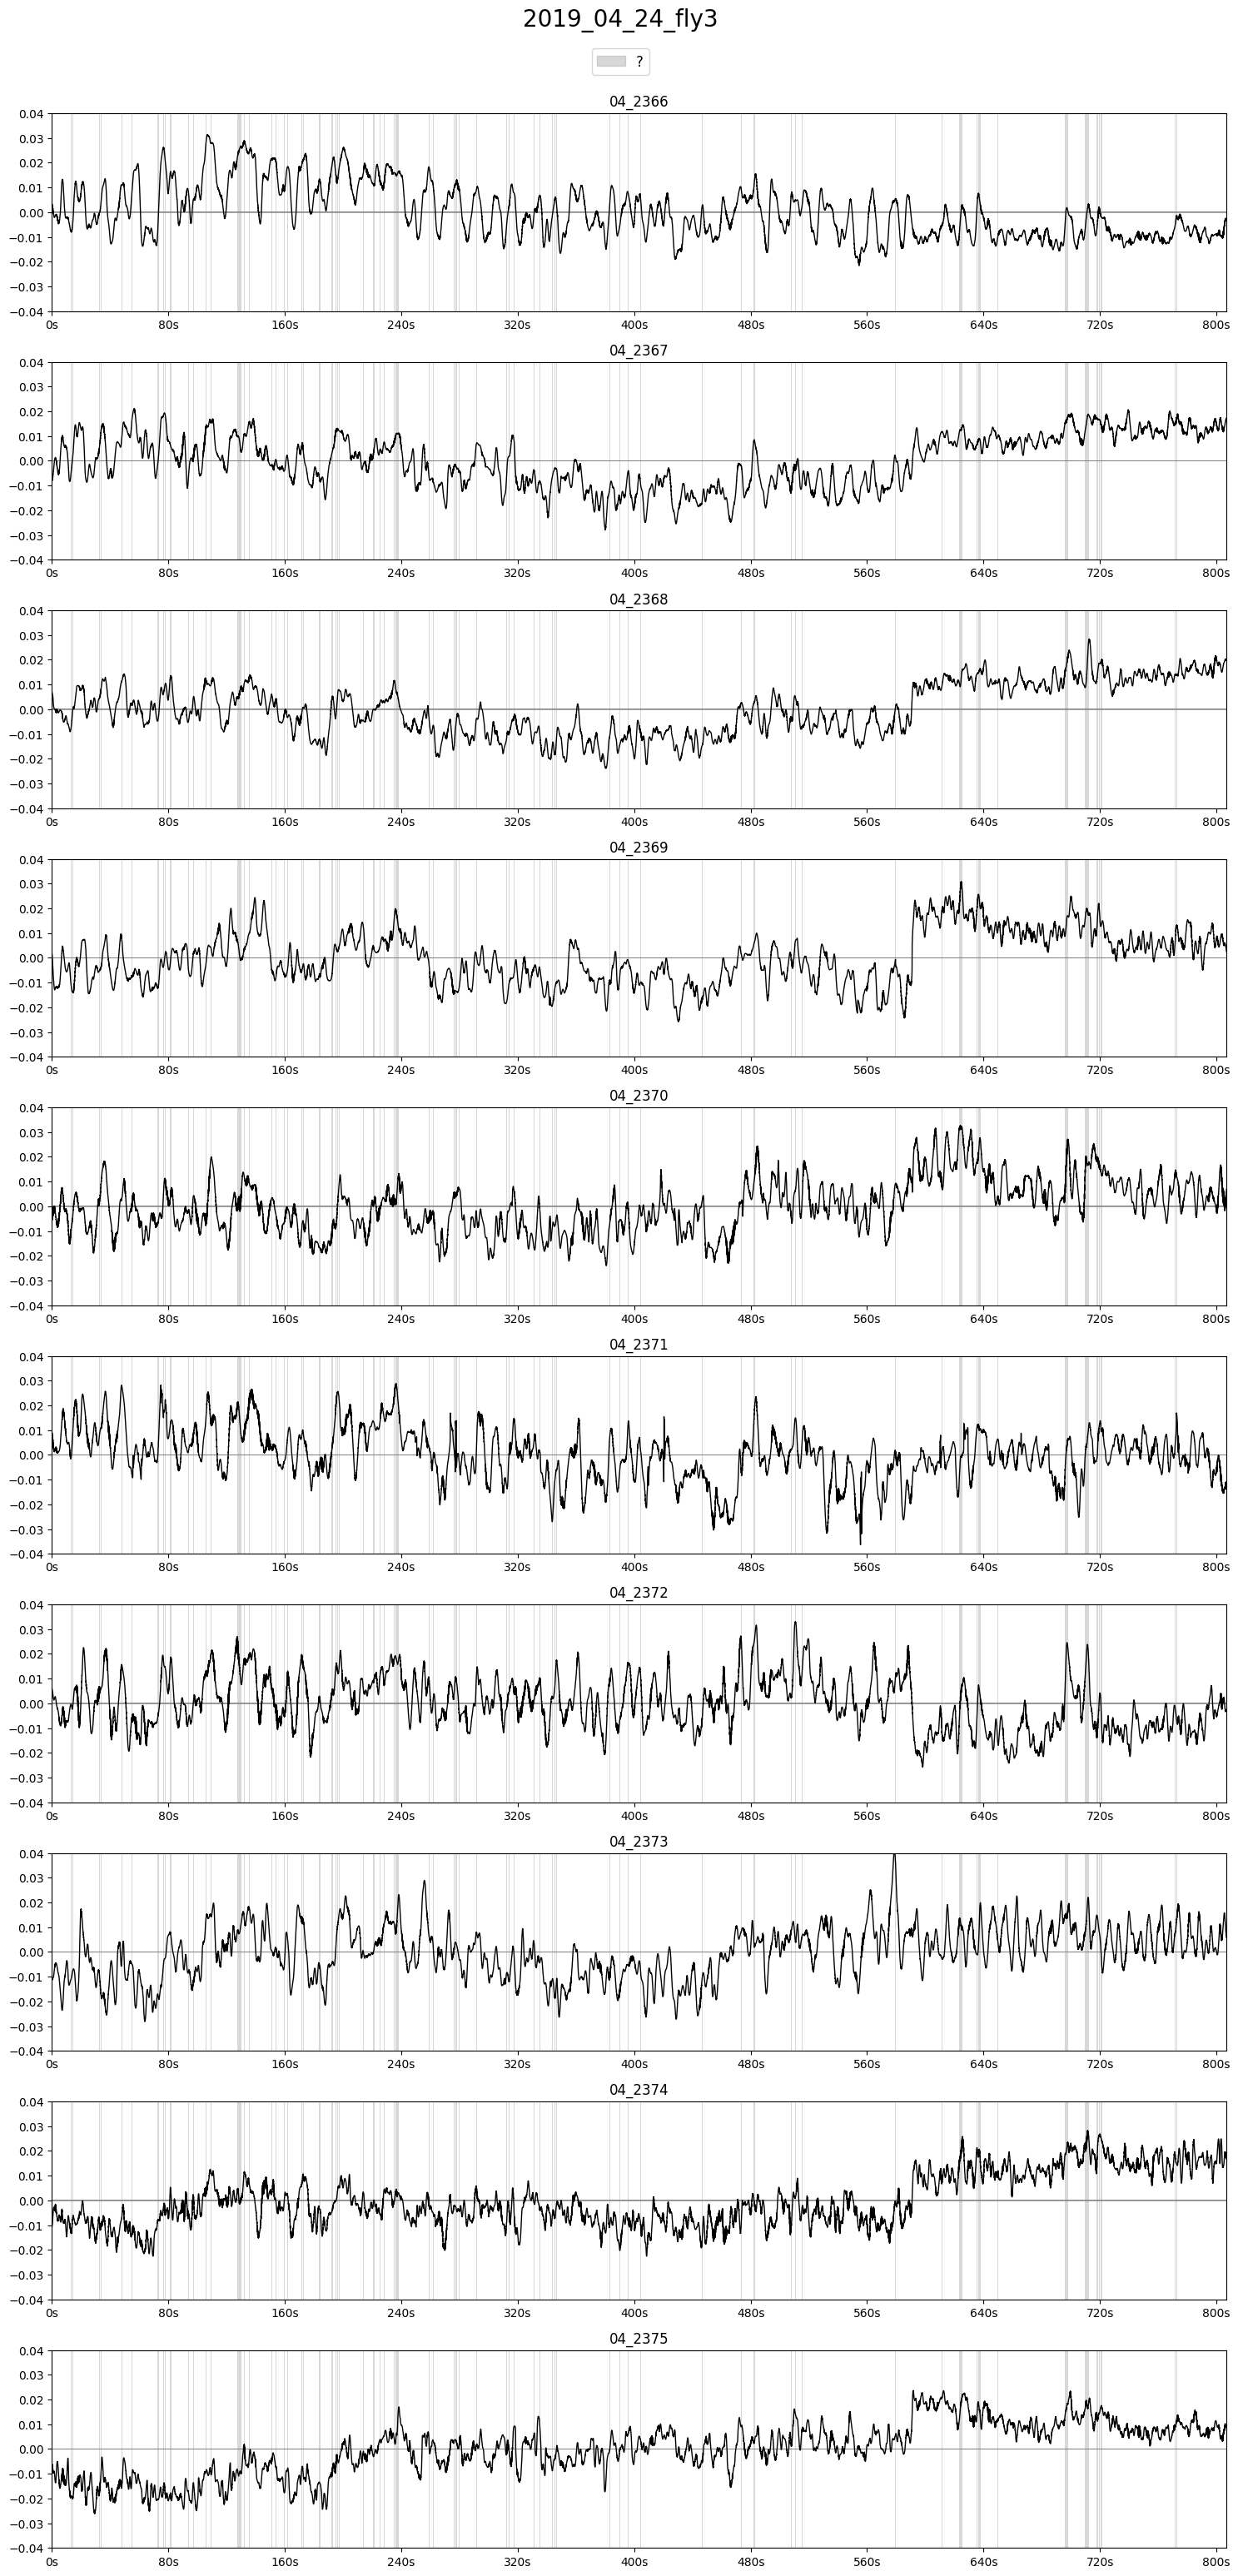

In [27]:
plot_utils.plot_traces(traces_fl.iloc[:, -10:],
					   states_fl['?'],
					   timestamps,
					   label='?',
					   title=f'{filename_fl}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))